In [1]:
import pandas as pd

df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
print("Dataset shape:", df.shape)

print("\nData types:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (7043, 21)

Data types:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilli

In [3]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print("TotalCharges data type:", df["TotalCharges"].dtype)
print("Missing values after conversion:", df["TotalCharges"].isnull().sum())

TotalCharges data type: float64
Missing values after conversion: 11


In [4]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Missing values:", df["TotalCharges"].isnull().sum())

Missing values: 0


In [5]:
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nChurn distribution:")
print(y.value_counts())

X shape: (7043, 19)
y shape: (7043,)

Churn distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (5634, 19)
X_test: (1409, 19)
y_train: (5634,)
y_test: (1409,)


In [7]:
categorical_features = X_train.select_dtypes(include="str").columns.tolist()

numerical_features = X_train.select_dtypes(exclude="str").columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumber of categorical features:", len(categorical_features))

print("\nNumerical features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Number of categorical features: 15

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Number of numerical features: 4


In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [9]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print(model_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtection',
                               

In [10]:
model_pipeline.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [11]:
y_pred = model_pipeline.predict(X_test)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 predictions:")
print(y_pred[:10].tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 predictions:
[0, 1, 0, 0, 0, 1, 0, 0, 0, 0]


In [12]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy percentage: {accuracy * 100:.2f}%")

Accuracy: 0.8055
Accuracy percentage: 80.55%


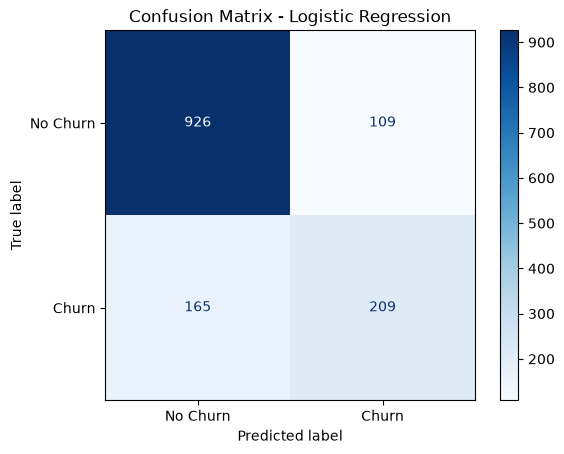

[[926 109]
 [165 209]]


In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

print(cm)

In [14]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"]
))

              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



In [15]:
y_prob = model_pipeline.predict_proba(X_test)

print("First 10 churn probabilities:")
print(y_prob[:10, 1])

First 10 churn probabilities:
[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [16]:
from sklearn.metrics import precision_score, recall_score, f1_score

threshold = 0.35

y_pred_035 = (y_prob[:, 1] >= threshold).astype(int)

print("Threshold:", threshold)
print("Precision:", round(precision_score(y_test, y_pred_035), 3))
print("Recall:", round(recall_score(y_test, y_pred_035), 3))
print("F1-score:", round(f1_score(y_test, y_pred_035), 3))

Threshold: 0.35
Precision: 0.543
Recall: 0.706
F1-score: 0.614


In [17]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("X_fit:", X_fit.shape)
print("X_val:", X_val.shape)
print("y_fit:", y_fit.shape)
print("y_val:", y_val.shape)

X_fit: (4507, 19)
X_val: (1127, 19)
y_fit: (4507,)
y_val: (1127,)


In [18]:
validation_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

validation_pipeline.fit(X_fit, y_fit)

print("Validation model trained successfully!")

Validation model trained successfully!


In [20]:
y_val_prob = validation_pipeline.predict_proba(X_val)[:, 1]

print("First 10 validation churn probabilities:")
print(y_val_prob[:10])

First 10 validation churn probabilities:
[0.19633402 0.01864361 0.05275316 0.16712534 0.25490166 0.03505654
 0.17676777 0.01422864 0.01536907 0.24499299]


In [21]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.50, 0.40, 0.35, 0.30]

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision:.3f} | "
        f"Recall: {recall:.3f} | "
        f"F1-score: {f1:.3f}"
    )

Threshold: 0.50 | Precision: 0.694 | Recall: 0.545 | F1-score: 0.610
Threshold: 0.40 | Precision: 0.617 | Recall: 0.669 | F1-score: 0.642
Threshold: 0.35 | Precision: 0.579 | Recall: 0.709 | F1-score: 0.638
Threshold: 0.30 | Precision: 0.545 | Recall: 0.756 | F1-score: 0.633


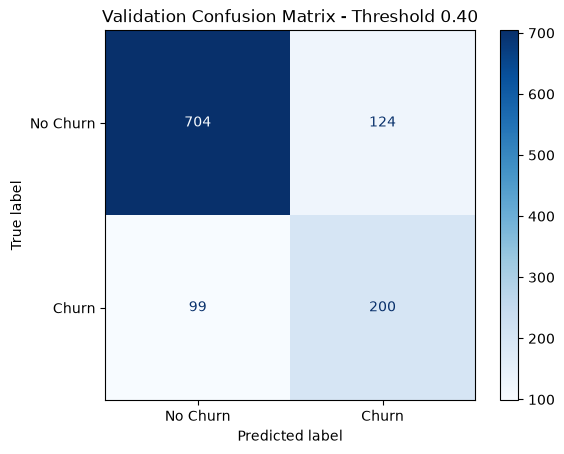

[[704 124]
 [ 99 200]]


In [22]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

selected_threshold = 0.40

y_val_pred_selected = (
    y_val_prob >= selected_threshold
).astype(int)

cm_val = confusion_matrix(y_val, y_val_pred_selected)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm_val,
    display_labels=["No Churn", "Churn"]
)

display.plot(cmap="Blues")
plt.title("Validation Confusion Matrix - Threshold 0.40")
plt.show()

print(cm_val)

In [23]:
final_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

final_pipeline.fit(X_train, y_train)

print("Final model trained successfully!")

Final model trained successfully!


In [24]:
y_test_prob_final = final_pipeline.predict_proba(X_test)[:, 1]

print("First 10 test churn probabilities:")
print(y_test_prob_final[:10])

First 10 test churn probabilities:
[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]


In [25]:
final_threshold = 0.40

y_test_pred_final = (
    y_test_prob_final >= final_threshold
).astype(int)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 final predictions:")
print(y_test_pred_final[:10].tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 final predictions:
[0, 1, 0, 1, 0, 1, 1, 0, 0, 0]


In [26]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

print("Final Threshold:", final_threshold)
print("Accuracy:", round(accuracy_score(y_test, y_test_pred_final), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_test_prob_final), 3))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_final,
    target_names=["No Churn", "Churn"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred_final))

Final Threshold: 0.4
Accuracy: 0.777
ROC-AUC: 0.842

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.87      0.82      0.84      1035
       Churn       0.57      0.67      0.61       374

    accuracy                           0.78      1409
   macro avg       0.72      0.74      0.73      1409
weighted avg       0.79      0.78      0.78      1409

Confusion Matrix:
[[845 190]
 [124 250]]


In [27]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

tree_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=5,
            random_state=42
        ))
    ]
)

tree_pipeline.fit(X_train, y_train)

print("Decision Tree trained successfully!")

Decision Tree trained successfully!


In [28]:
tree_test_prob = tree_pipeline.predict_proba(X_test)[:, 1]

tree_test_pred = (
    tree_test_prob >= final_threshold
).astype(int)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 Decision Tree predictions:")
print(tree_test_pred[:10].tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 Decision Tree predictions:
[0, 1, 0, 1, 0, 0, 0, 0, 0, 0]


In [29]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Decision Tree Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, tree_test_pred), 3))
print("Precision:", round(precision_score(y_test, tree_test_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, tree_test_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, tree_test_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, tree_test_prob), 3))

Decision Tree Results
---------------------
Accuracy: 0.788
Precision: 0.598
Recall: 0.612
F1-score: 0.605
ROC-AUC: 0.83


In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

rf_pipeline.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [31]:
rf_test_prob = rf_pipeline.predict_proba(X_test)[:, 1]

rf_test_pred = (
    rf_test_prob >= final_threshold
).astype(int)

print("First 10 actual values:")
print(y_test.iloc[:10].tolist())

print("\nFirst 10 Random Forest predictions:")
print(rf_test_pred[:10].tolist())

First 10 actual values:
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]

First 10 Random Forest predictions:
[0, 1, 0, 0, 0, 0, 0, 0, 0, 1]


In [32]:
print("Random Forest Results")
print("---------------------")
print("Accuracy:", round(accuracy_score(y_test, rf_test_pred), 3))
print("Precision:", round(precision_score(y_test, rf_test_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, rf_test_pred, zero_division=0), 3))
print("F1-score:", round(f1_score(y_test, rf_test_pred, zero_division=0), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_test_prob), 3))

Random Forest Results
---------------------
Accuracy: 0.769
Precision: 0.56
Recall: 0.599
F1-score: 0.579
ROC-AUC: 0.821


In [33]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", LogisticRegression(max_iter=1000))
        ]
    ),
    param_grid=param_grid,
    cv=5,
    scoring="roc_auc",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best cross-validation ROC-AUC:", round(grid_search.best_score_, 3))

Best parameters: {'classifier__C': 10}
Best cross-validation ROC-AUC: 0.846


In [34]:
best_lr_pipeline = grid_search.best_estimator_

print("Best Logistic Regression pipeline:")
print(best_lr_pipeline)

print("\nBest C:", best_lr_pipeline.named_steps["classifier"].C)

Best Logistic Regression pipeline:
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['gender', 'Partner',
                                                   'Dependents', 'PhoneService',
                                                   'MultipleLines',
                                                   'InternetService',
                                                   'OnlineSecurity',
                                                   'OnlineBackup',
                                                   'DeviceProtectio

In [35]:
best_lr_test_prob = best_lr_pipeline.predict_proba(X_test)[:, 1]

best_lr_test_pred = (
    best_lr_test_prob >= final_threshold
).astype(int)

print("Accuracy:", round(
    accuracy_score(y_test, best_lr_test_pred), 3
))
print("Precision:", round(
    precision_score(y_test, best_lr_test_pred, zero_division=0), 3
))
print("Recall:", round(
    recall_score(y_test, best_lr_test_pred, zero_division=0), 3
))
print("F1-score:", round(
    f1_score(y_test, best_lr_test_pred, zero_division=0), 3
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, best_lr_test_prob), 3
))

Accuracy: 0.774
Precision: 0.564
Recall: 0.663
F1-score: 0.609
ROC-AUC: 0.841


In [36]:
comparison_df = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": accuracy_score(y_test, y_test_pred_final),
        "Precision": precision_score(y_test, y_test_pred_final),
        "Recall": recall_score(y_test, y_test_pred_final),
        "F1-score": f1_score(y_test, y_test_pred_final),
        "ROC-AUC": roc_auc_score(y_test, y_test_prob_final)
    },
    {
        "Model": "Tuned Logistic Regression",
        "Accuracy": accuracy_score(y_test, best_lr_test_pred),
        "Precision": precision_score(y_test, best_lr_test_pred),
        "Recall": recall_score(y_test, best_lr_test_pred),
        "F1-score": f1_score(y_test, best_lr_test_pred),
        "ROC-AUC": roc_auc_score(y_test, best_lr_test_prob)
    },
    {
        "Model": "Decision Tree",
        "Accuracy": accuracy_score(y_test, tree_test_pred),
        "Precision": precision_score(y_test, tree_test_pred),
        "Recall": recall_score(y_test, tree_test_pred),
        "F1-score": f1_score(y_test, tree_test_pred),
        "ROC-AUC": roc_auc_score(y_test, tree_test_prob)
    },
    {
        "Model": "Random Forest",
        "Accuracy": accuracy_score(y_test, rf_test_pred),
        "Precision": precision_score(y_test, rf_test_pred),
        "Recall": recall_score(y_test, rf_test_pred),
        "F1-score": f1_score(y_test, rf_test_pred),
        "ROC-AUC": roc_auc_score(y_test, rf_test_prob)
    }
])

comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.777,0.568,0.668,0.614,0.842
1,Tuned Logistic Regression,0.774,0.564,0.663,0.609,0.841
2,Decision Tree,0.788,0.598,0.612,0.605,0.830
3,Random Forest,0.769,0.560,0.599,0.579,0.821


In [37]:
import os
import joblib

os.makedirs("../models", exist_ok=True)

joblib.dump(
    final_pipeline,
    "../models/churn_pipeline.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [38]:
loaded_pipeline = joblib.load(
    "../models/churn_pipeline.pkl"
)

print("Loaded model type:", type(loaded_pipeline))
print("Model loaded successfully!")

Loaded model type: <class 'sklearn.pipeline.Pipeline'>
Model loaded successfully!


In [39]:
loaded_prob = loaded_pipeline.predict_proba(X_test)[:, 1]

loaded_pred = (
    loaded_prob >= final_threshold
).astype(int)

print("First 10 predictions:", loaded_pred[:10].tolist())

print(
    "Predictions match:",
    (loaded_pred == y_test_pred_final).all()
)

First 10 predictions: [0, 1, 0, 1, 0, 1, 1, 0, 0, 0]
Predictions match: True
